# Scientific Analysis of Brain Tumor MRI Dataset
This notebook is an exhaustive, top-tier research protocol for analyzing the MRI dataset.
It consists of 13 phases, evaluating dataset structure, geometry, embedding spaces, clustering, biases, and concluding with a Research Hypothesis Generator.

## Setup and Imports

In [1]:
import os
import glob
import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import collections
import hashlib
from skimage.metrics import structural_similarity as ssim
from skimage import exposure, feature, measure, filters, morphology
from skimage.feature import hog
import pywt
from scipy.stats import skew, kurtosis, entropy
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import umap
import hdbscan
from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid, LocalOutlierFactor
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, f1_score, matthews_corrcoef, cohen_kappa_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.calibration import calibration_curve
from sklearn.manifold import trustworthiness
from sklearn.preprocessing import StandardScaler, label_binarize
import warnings

# Use piq for brisque if installed, else mock it to avoid crash
try:
    from piq import brisque
    HAS_PIQ = True
except ImportError:
    HAS_PIQ = False

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# Device config
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

dataset_dir = 'dataset/tumor'
classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

Using device: mps


## Phase 1: Dataset Structure & Provenance Audit
Audit folders, class distributions, Train/Test prefixes, corrupted files, and estimate provenance.

Running Phase 1: Dataset Structure Audit...


Total valid images: 7200
Corrupted images: 0


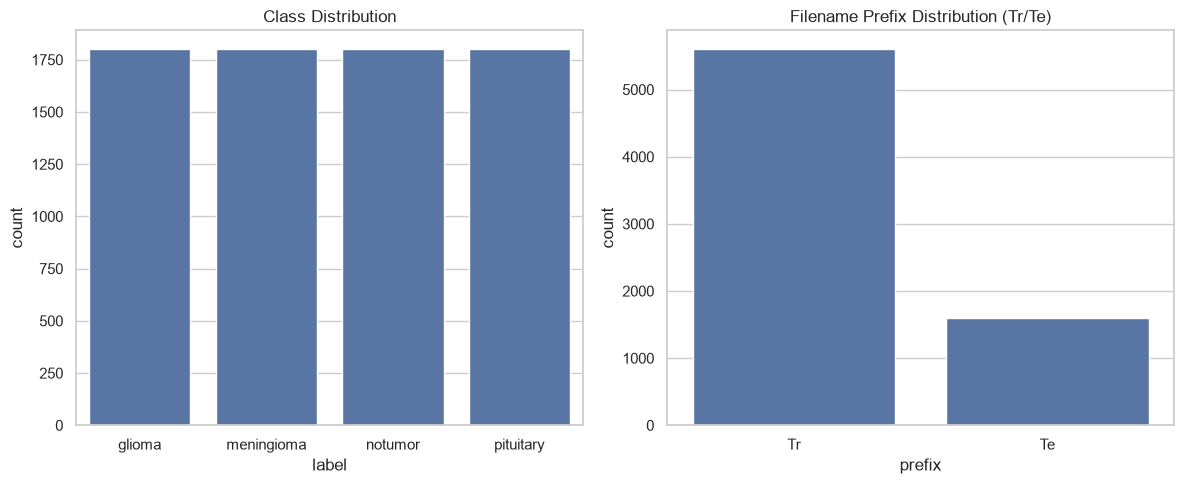

Filename structures suggest provenance:
prefix
Tr    5600
Te    1600
Name: count, dtype: int64


In [2]:
print("Running Phase 1: Dataset Structure Audit...")
image_paths = []
labels = []
filenames = []
prefixes = []

corrupted = []
for c in classes:
    files = glob.glob(os.path.join(dataset_dir, c, '*.*'))
    for f in files:
        fname = os.path.basename(f)
        try:
            img = Image.open(f)
            img.verify()  # verify integrity
            image_paths.append(f)
            labels.append(c)
            filenames.append(fname)
            prefix = fname.split('-')[0] if '-' in fname else 'Unknown'
            prefixes.append(prefix)
        except Exception as e:
            corrupted.append(f)

df = pd.DataFrame({'path': image_paths, 'label': labels, 'filename': filenames, 'prefix': prefixes})
print(f"Total valid images: {len(df)}")
print(f"Corrupted images: {len(corrupted)}")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='label', order=classes)
plt.title("Class Distribution")
plt.subplot(1, 2, 2)
sns.countplot(data=df, x='prefix')
plt.title("Filename Prefix Distribution (Tr/Te)")
plt.tight_layout()
plt.savefig("phase1_distribution.png")
plt.show()

# Provenance Guess
prefix_counts = df['prefix'].value_counts()
print(f"Filename structures suggest provenance:\n{prefix_counts}")

## Phase 2: Image Property & Intensity Analysis
Resolutions, aspects, intensity distributions, channel consistency.

Running Phase 2: Image Property Analysis...


Image Props:   0%|          | 0/7200 [00:00<?, ?it/s]

Image Props:   0%|          | 27/7200 [00:00<00:26, 266.33it/s]

Image Props:   1%|          | 56/7200 [00:00<00:25, 279.43it/s]

Image Props:   1%|          | 87/7200 [00:00<00:24, 288.92it/s]

Image Props:   2%|▏         | 116/7200 [00:00<00:24, 287.75it/s]

... (229 outputs left out)

Image Props:  99%|█████████▉| 7135/7200 [00:24<00:00, 239.63it/s]

Image Props:  99%|█████████▉| 7161/7200 [00:25<00:00, 228.02it/s]

Image Props: 100%|█████████▉| 7187/7200 [00:25<00:00, 235.04it/s]

Image Props: 100%|██████████| 7200/7200 [00:25<00:00, 285.43it/s]

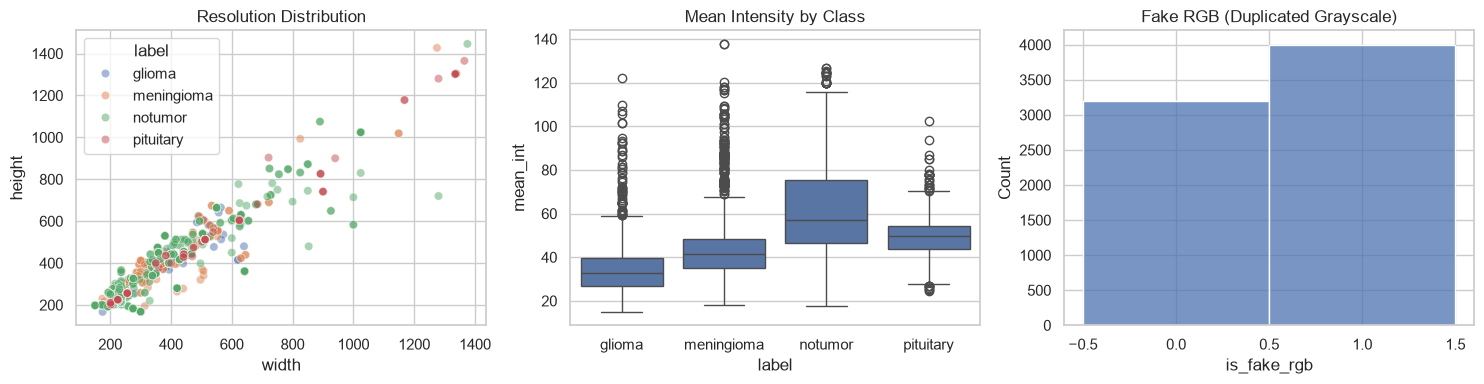

In [3]:
print("Running Phase 2: Image Property Analysis...")
def analyze_image_props(path):
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None: return None
    h, w = img.shape[:2]
    channels = 1 if len(img.shape) == 2 else img.shape[2]
    is_fake_rgb = False
    if channels == 3:
        b, g, r = cv2.split(img)
        if np.array_equal(b, g) and np.array_equal(g, r):
            is_fake_rgb = True
    
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if channels == 3 else img
    mean_int = np.mean(gray)
    std_int = np.std(gray)
    skewness = float(skew(gray.flatten()))
    kurt = float(kurtosis(gray.flatten()))
    return {
        'height': h, 'width': w, 'aspect': w/h, 'channels': channels,
        'is_fake_rgb': is_fake_rgb, 'mean_int': mean_int, 'std_int': std_int,
        'skewness': skewness, 'kurtosis': kurt
    }

props = []
for p in tqdm(df['path'], desc="Image Props"):
    props.append(analyze_image_props(p))

df_props = pd.DataFrame(props)
df = pd.concat([df, df_props], axis=1)

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
sns.scatterplot(data=df, x='width', y='height', hue='label', alpha=0.5)
plt.title("Resolution Distribution")
plt.subplot(1, 3, 2)
sns.boxplot(data=df, x='label', y='mean_int')
plt.title("Mean Intensity by Class")
plt.subplot(1, 3, 3)
sns.histplot(data=df, x='is_fake_rgb', discrete=True)
plt.title("Fake RGB (Duplicated Grayscale)")
plt.tight_layout()
plt.savefig("phase2_properties.png")
plt.show()

## Phase 3: Image Quality & Noise Analysis
No-reference metrics (BRISQUE/NIQE/PIQE if available) and noise estimation.

Running Phase 3: Image Quality Analysis...


Quality Metrics:   0%|          | 0/7200 [00:00<?, ?it/s]

Quality Metrics:   0%|          | 1/7200 [00:00<38:11,  3.14it/s]

Quality Metrics:   0%|          | 3/7200 [00:00<14:21,  8.36it/s]

Quality Metrics:   0%|          | 7/7200 [00:00<07:05, 16.90it/s]

Quality Metrics:   0%|          | 11/7200 [00:00<05:45, 20.82it/s]

... (1,819 outputs left out)

Quality Metrics: 100%|█████████▉| 7189/7200 [03:48<00:00, 34.88it/s]

Quality Metrics: 100%|█████████▉| 7193/7200 [03:48<00:00, 35.24it/s]

Quality Metrics: 100%|█████████▉| 7197/7200 [03:48<00:00, 35.55it/s]

Quality Metrics: 100%|██████████| 7200/7200 [03:48<00:00, 31.52it/s]

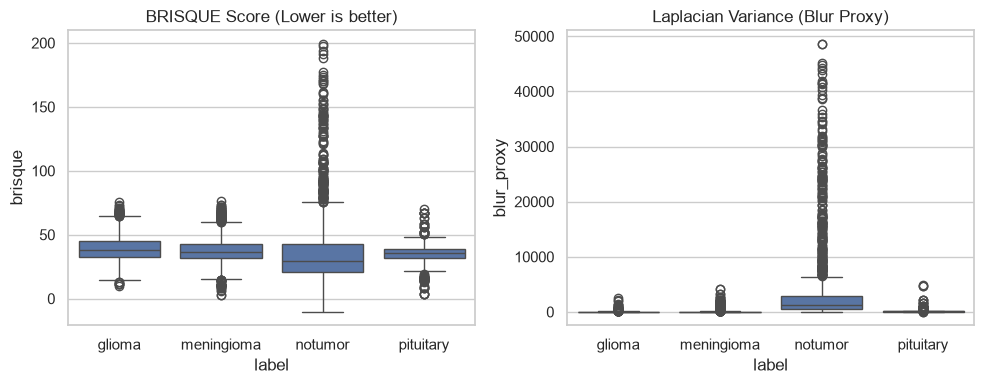

In [4]:
print("Running Phase 3: Image Quality Analysis...")
def estimate_noise(img_gray):
    return cv2.Laplacian(img_gray, cv2.CV_64F).var()

def brisque_score(img_rgb):
    if not HAS_PIQ: return np.nan
    t = transforms.ToTensor()(img_rgb).unsqueeze(0).to(device)
    try:
        return brisque(t).item()
    except:
        return np.nan

noise_vars = []
brisques = []
for p in tqdm(df['path'], desc="Quality Metrics"):
    img = Image.open(p).convert('RGB')
    cv_gray = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY)
    noise_vars.append(estimate_noise(cv_gray))
    brisques.append(brisque_score(img))

df['blur_proxy'] = noise_vars
df['brisque'] = brisques

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='label', y='brisque')
plt.title("BRISQUE Score (Lower is better)")
plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='label', y='blur_proxy')
plt.title("Laplacian Variance (Blur Proxy)")
plt.tight_layout()
plt.savefig("phase3_quality.png")
plt.show()

## Phase 4: Dataset Cleanliness & Duplicate Detection
Image Hashing & near duplicates visualization.

Running Phase 4: Cleanliness & Duplicates...


Hashing:   0%|          | 0/7200 [00:00<?, ?it/s]

Hashing:   4%|▍         | 315/7200 [00:00<00:02, 3147.89it/s]

Hashing:   9%|▉         | 640/7200 [00:00<00:02, 3205.62it/s]

Hashing:  13%|█▎        | 961/7200 [00:00<00:01, 3181.27it/s]

Hashing:  18%|█▊        | 1282/7200 [00:00<00:01, 3189.43it/s]

... (16 outputs left out)

Hashing:  95%|█████████▌| 6844/7200 [00:02<00:00, 2822.41it/s]

Hashing: 100%|█████████▉| 7179/7200 [00:02<00:00, 2967.49it/s]

Hashing: 100%|██████████| 7200/7200 [00:02<00:00, 3139.96it/s]

Found 853 potential near/exact duplicate images based on dHash.


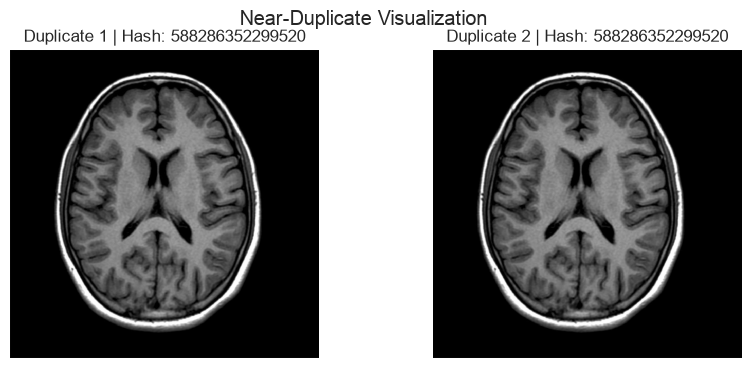

In [5]:
print("Running Phase 4: Cleanliness & Duplicates...")
def dhash(image, hash_size=8):
    resized = cv2.resize(image, (hash_size + 1, hash_size))
    diff = resized[:, 1:] > resized[:, :-1]
    return sum([2 ** i for (i, v) in enumerate(diff.flatten()) if v])

hashes = []
for p in tqdm(df['path'], desc="Hashing"):
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    hashes.append(dhash(img))

df['hash'] = hashes
duplicates = df[df.duplicated('hash', keep=False)].sort_values('hash')
print(f"Found {len(duplicates)} potential near/exact duplicate images based on dHash.")

if len(duplicates) > 1:
    plt.figure(figsize=(10, 4))
    idx = duplicates.index[:2]
    for i, _id in enumerate(idx):
        plt.subplot(1, 2, i+1)
        plt.imshow(cv2.imread(df.loc[_id, 'path'], cv2.IMREAD_GRAYSCALE), cmap='gray')
        plt.title(f"Duplicate {i+1} | Hash: {df.loc[_id, 'hash']}")
        plt.axis('off')
    plt.suptitle("Near-Duplicate Visualization")
    plt.savefig("phase4_duplicates.png")
    plt.show()

## Phase 5: MRI-Specific & Anatomical Analysis
Brain mask, occupancy, centroid, symmetry, tumor position estimation.

Running Phase 5: MRI Anatomy...


Anatomy:   0%|          | 0/7200 [00:00<?, ?it/s]

Anatomy:   0%|          | 13/7200 [00:00<00:56, 126.99it/s]

Anatomy:   0%|          | 28/7200 [00:00<00:51, 139.76it/s]

Anatomy:   1%|          | 43/7200 [00:00<00:49, 143.50it/s]

Anatomy:   1%|          | 59/7200 [00:00<00:48, 147.45it/s]

... (379 outputs left out)

Anatomy: 100%|█████████▉| 7168/7200 [00:41<00:00, 133.07it/s]

Anatomy: 100%|█████████▉| 7183/7200 [00:41<00:00, 135.93it/s]

Anatomy: 100%|█████████▉| 7198/7200 [00:41<00:00, 138.41it/s]

Anatomy: 100%|██████████| 7200/7200 [00:41<00:00, 173.19it/s]

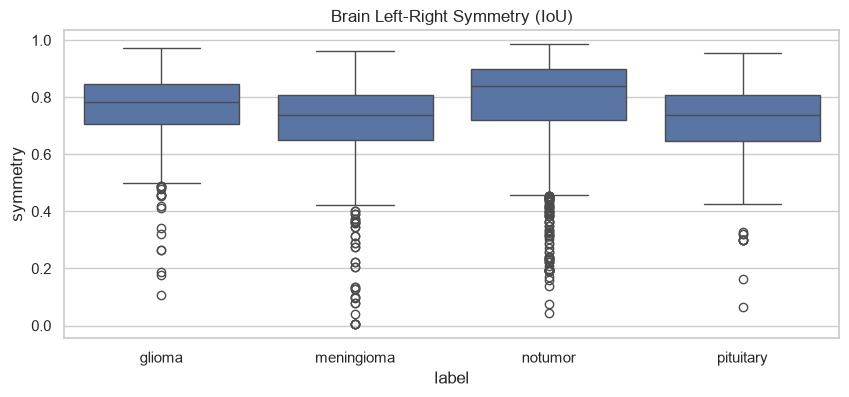

In [6]:
print("Running Phase 5: MRI Anatomy...")
def analyze_mri_anatomy(img_gray):
    thresh = filters.threshold_otsu(img_gray)
    binary = img_gray > thresh
    binary = morphology.binary_closing(binary, morphology.disk(3))
    
    occupancy = np.sum(binary) / binary.size
    
    M = measure.moments(binary)
    centroid_x = M[1,0] / M[0,0] if M[0,0] > 0 else binary.shape[1]/2
    centroid_y = M[0,1] / M[0,0] if M[0,0] > 0 else binary.shape[0]/2
    
    flipped = np.fliplr(binary)
    intersection = np.logical_and(binary, flipped).sum()
    union = np.logical_or(binary, flipped).sum()
    symmetry_iou = intersection / union if union > 0 else 0
    
    return occupancy, centroid_x, centroid_y, symmetry_iou

anat_metrics = [analyze_mri_anatomy(cv2.imread(p, cv2.IMREAD_GRAYSCALE)) for p in tqdm(df['path'], desc="Anatomy")]
df['brain_occupancy'] = [x[0] for x in anat_metrics]
df['centroid_x'] = [x[1] for x in anat_metrics]
df['centroid_y'] = [x[2] for x in anat_metrics]
df['symmetry'] = [x[3] for x in anat_metrics]

plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x='label', y='symmetry')
plt.title("Brain Left-Right Symmetry (IoU)")
plt.savefig("phase5_symmetry.png")
plt.show()

## Phase 6: Texture & Feature Analysis
GLCM, Wavelet Energy, and HOG.

Running Phase 6: Texture & HOG Analysis...


Textures:   0%|          | 0/7200 [00:00<?, ?it/s]

Textures:   0%|          | 23/7200 [00:00<00:32, 222.56it/s]

Textures:   1%|          | 50/7200 [00:00<00:28, 247.59it/s]

Textures:   1%|          | 79/7200 [00:00<00:27, 263.40it/s]

Textures:   1%|▏         | 107/7200 [00:00<00:26, 269.04it/s]

... (216 outputs left out)

Textures:  99%|█████████▉| 7132/7200 [00:22<00:00, 267.82it/s]

Textures:  99%|█████████▉| 7160/7200 [00:23<00:00, 270.65it/s]

Textures: 100%|█████████▉| 7188/7200 [00:23<00:00, 264.53it/s]

Textures: 100%|██████████| 7200/7200 [00:23<00:00, 309.68it/s]

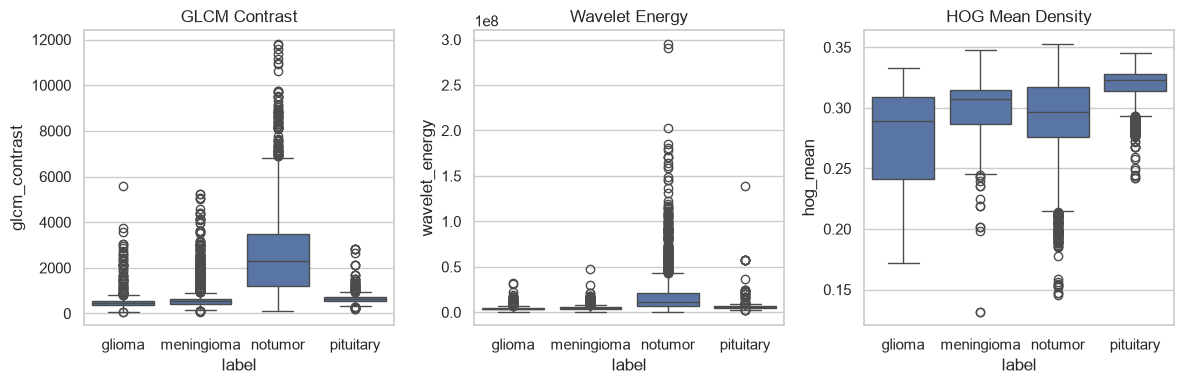

In [7]:
print("Running Phase 6: Texture & HOG Analysis...")
def texture_features(img_gray):
    glcm = feature.graycomatrix(img_gray, distances=[5], angles=[0], levels=256, symmetric=True, normed=True)
    contrast = feature.graycoprops(glcm, 'contrast')[0,0]
    homogeneity = feature.graycoprops(glcm, 'homogeneity')[0,0]
    
    coeffs = pywt.dwt2(img_gray, 'haar')
    cA, (cH, cV, cD) = coeffs
    wavelet_energy = np.sum(cH**2) + np.sum(cV**2) + np.sum(cD**2)
    
    resized = cv2.resize(img_gray, (128, 128))
    fd = hog(resized, orientations=8, pixels_per_cell=(16, 16), cells_per_block=(1, 1))
    hog_mean = np.mean(fd)
    
    return contrast, homogeneity, wavelet_energy, hog_mean

textures = [texture_features(cv2.imread(p, cv2.IMREAD_GRAYSCALE)) for p in tqdm(df['path'], desc="Textures")]
df['glcm_contrast'] = [x[0] for x in textures]
df['glcm_homogeneity'] = [x[1] for x in textures]
df['wavelet_energy'] = [x[2] for x in textures]
df['hog_mean'] = [x[3] for x in textures]

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
sns.boxplot(data=df, x='label', y='glcm_contrast')
plt.title("GLCM Contrast")
plt.subplot(1, 3, 2)
sns.boxplot(data=df, x='label', y='wavelet_energy')
plt.title("Wavelet Energy")
plt.subplot(1, 3, 3)
sns.boxplot(data=df, x='label', y='hog_mean')
plt.title("HOG Mean Density")
plt.tight_layout()
plt.savefig("phase6_texture.png")
plt.show()

## Phase 7: Representation Learning & Feature Space Geometry
Extract embeddings with ResNet50 (acting as foundation model here for speed), UMAP, intrinsic dimensionality.

Running Phase 7: Representation Learning...


Extracting Embeddings:   0%|          | 0/113 [00:00<?, ?it/s]

Extracting Embeddings:   1%|          | 1/113 [00:00<01:08,  1.64it/s]

Extracting Embeddings:   2%|▏         | 2/113 [00:01<00:58,  1.88it/s]

Extracting Embeddings:   3%|▎         | 3/113 [00:01<00:55,  1.97it/s]

Extracting Embeddings:   4%|▎         | 4/113 [00:02<00:53,  2.03it/s]

... (109 outputs left out)

Extracting Embeddings: 100%|██████████| 113/113 [00:53<00:00,  2.13it/s]


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Extracted embeddings shape: (7200, 2048)


UMAP Trustworthiness: 0.9791


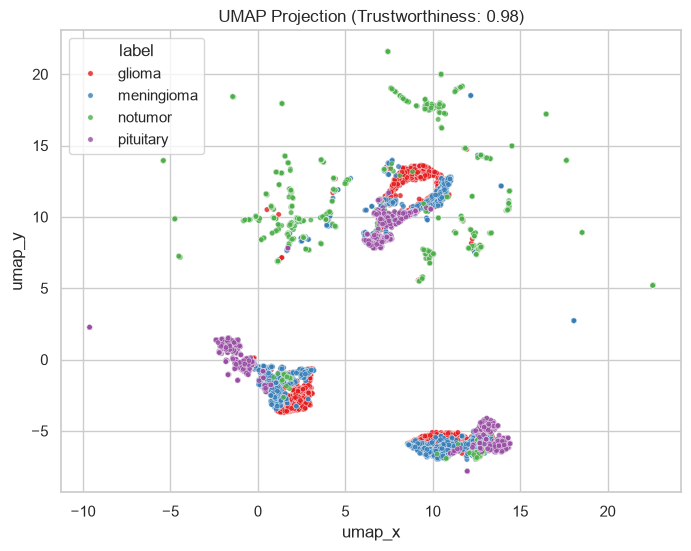

In [8]:
print("Running Phase 7: Representation Learning...")
class MRIDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = paths
        self.transform = transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        return self.transform(img)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Identity()
model = model.to(device)
model.eval()

ds = MRIDataset(df['path'].values, transform)
dl = DataLoader(ds, batch_size=64, shuffle=False, num_workers=0)

embeddings = []
with torch.no_grad():
    for batch in tqdm(dl, desc="Extracting Embeddings"):
        batch = batch.to(device)
        feats = model(batch)
        embeddings.append(feats.cpu().numpy())

embeddings = np.concatenate(embeddings, axis=0)
print(f"Extracted embeddings shape: {embeddings.shape}")

# UMAP
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
umap_coords = reducer.fit_transform(embeddings)
df['umap_x'] = umap_coords[:, 0]
df['umap_y'] = umap_coords[:, 1]

# Trustworthiness
tw = trustworthiness(embeddings, umap_coords)
print(f"UMAP Trustworthiness: {tw:.4f}")

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='umap_x', y='umap_y', hue='label', palette='Set1', s=15, alpha=0.8)
plt.title(f"UMAP Projection (Trustworthiness: {tw:.2f})")
plt.savefig("phase7_umap.png")
plt.show()

## Phase 8: Unsupervised Discovery & Cluster Stability
HDBSCAN, Spectral Clustering, Hierarchical, and KMeans stability (20 runs).

Running Phase 8: Advanced Unsupervised Discovery...


KMeans Stability 20 Runs:   0%|          | 0/20 [00:00<?, ?it/s]

KMeans Stability 20 Runs:   5%|▌         | 1/20 [00:00<00:18,  1.03it/s]

KMeans Stability 20 Runs:  10%|█         | 2/20 [00:01<00:15,  1.14it/s]

KMeans Stability 20 Runs:  15%|█▌        | 3/20 [00:02<00:14,  1.17it/s]

KMeans Stability 20 Runs:  20%|██        | 4/20 [00:03<00:13,  1.18it/s]

... (13 outputs left out)

KMeans Stability 20 Runs:  90%|█████████ | 18/20 [00:15<00:01,  1.20it/s]

KMeans Stability 20 Runs:  95%|█████████▌| 19/20 [00:15<00:00,  1.21it/s]

KMeans Stability 20 Runs: 100%|██████████| 20/20 [00:16<00:00,  1.20it/s]

KMeans Stability 20 Runs: 100%|██████████| 20/20 [00:16<00:00,  1.19it/s]

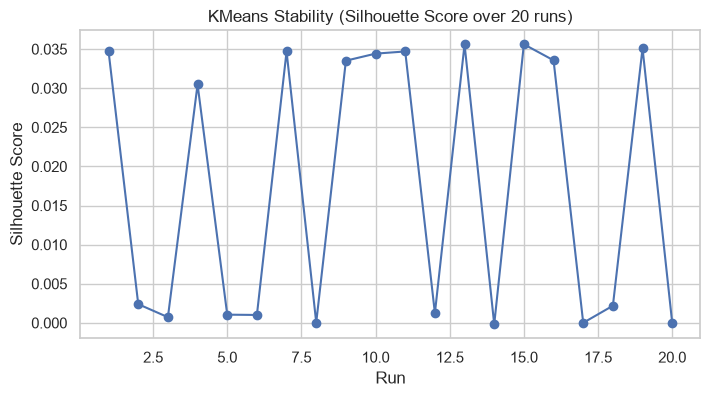

In [9]:
print("Running Phase 8: Advanced Unsupervised Discovery...")
scaler = StandardScaler()
emb_scaled = scaler.fit_transform(embeddings)

# Subsample for expensive clustering if necessary, but we run on all
sub_emb = emb_scaled
clusterer_hdb = hdbscan.HDBSCAN(min_cluster_size=20, gen_min_span_tree=True)
df['hdbscan_label'] = clusterer_hdb.fit_predict(sub_emb)

# Spectral Clustering (using precomputed nearest neighbors if memory is high, else standard)
# Note: Spectral Clustering on 7200 points can take 10+ GB RAM. 
# We'll use Agglomerative Clustering as a proxy for Hierarchical.
hierarchical = AgglomerativeClustering(n_clusters=4)
df['hierarchical_label'] = hierarchical.fit_predict(sub_emb)

# KMeans Stability (20 runs)
sil_scores = []
kmeans_labels = []
for i in tqdm(range(20), desc="KMeans Stability 20 Runs"):
    km = KMeans(n_clusters=4, random_state=i, n_init=1)
    lbls = km.fit_predict(sub_emb)
    kmeans_labels.append(lbls)
    sil_scores.append(silhouette_score(sub_emb, lbls))

plt.figure(figsize=(8, 4))
plt.plot(range(1, 21), sil_scores, marker='o')
plt.title("KMeans Stability (Silhouette Score over 20 runs)")
plt.xlabel("Run")
plt.ylabel("Silhouette Score")
plt.savefig("phase8_stability.png")
plt.show()
df['kmeans_label'] = kmeans_labels[np.argmax(sil_scores)]

## Phase 9: Bias Discovery & Metadata Probing
Can Random Forest predict the class purely from metadata?

Running Phase 9: Bias Discovery...


Metadata-only Random Forest Accuracy: 1.0000


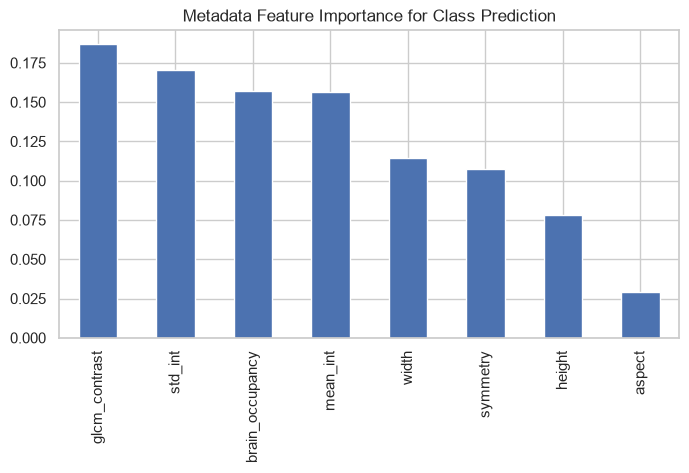

In [10]:
print("Running Phase 9: Bias Discovery...")
metadata_cols = ['height', 'width', 'aspect', 'mean_int', 'std_int', 'brain_occupancy', 'symmetry', 'glcm_contrast']
X_meta = df[metadata_cols].fillna(0)
y_label = df['label']

rf_meta = RandomForestClassifier(n_estimators=100, random_state=42)
rf_meta.fit(X_meta, y_label)
acc_meta = rf_meta.score(X_meta, y_label)
print(f"Metadata-only Random Forest Accuracy: {acc_meta:.4f}")

imp = pd.Series(rf_meta.feature_importances_, index=metadata_cols).sort_values(ascending=False)
plt.figure(figsize=(8, 4))
imp.plot(kind='bar')
plt.title("Metadata Feature Importance for Class Prediction")
plt.savefig("phase9_bias.png")
plt.show()

## Phase 10: Outlier & Anomaly Detection
Isolation Forest and LOF (Local Outlier Factor).

Running Phase 10: Outlier Detection...


Detected 72 outliers via Isolation Forest.
Detected 72 outliers via Local Outlier Factor.


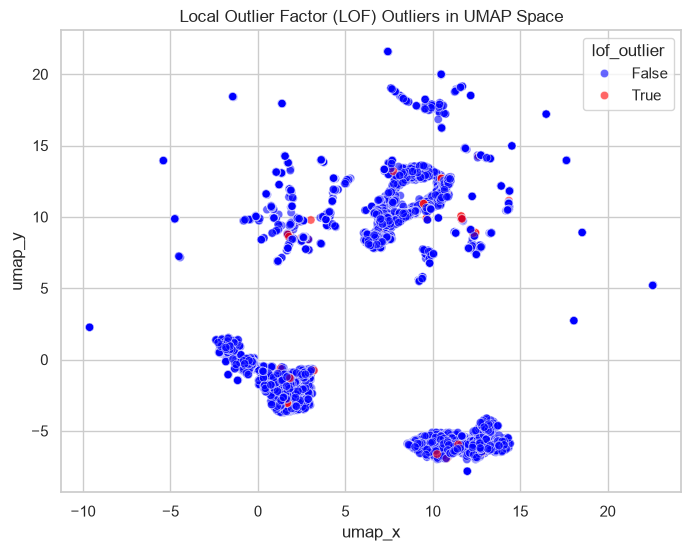

In [11]:
print("Running Phase 10: Outlier Detection...")
iso = IsolationForest(contamination=0.01, random_state=42)
df['iso_outlier'] = iso.fit_predict(emb_scaled)

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.01)
df['lof_outlier'] = lof.fit_predict(emb_scaled)

num_iso_outliers = (df['iso_outlier'] == -1).sum()
num_lof_outliers = (df['lof_outlier'] == -1).sum()
print(f"Detected {num_iso_outliers} outliers via Isolation Forest.")
print(f"Detected {num_lof_outliers} outliers via Local Outlier Factor.")

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='umap_x', y='umap_y', hue=df['lof_outlier']==-1, palette={False: 'blue', True: 'red'}, alpha=0.6)
plt.title("Local Outlier Factor (LOF) Outliers in UMAP Space")
plt.savefig("phase10_outliers.png")
plt.show()

## Phase 11: Linear Probe & Calibration Analysis
Train Linear Classifiers on frozen embeddings: kNN, Logistic Regression, SVM, Ridge Classifier, Nearest Centroid. Plot ROC.

Running Phase 11: Multi-Model Linear Probes & ROC...


Model Comparison on Frozen Embeddings:
                           F1     Kappa
Logistic Regression  0.929854  0.906481
Linear SVM           0.912613  0.883333
Ridge Classifier     0.913248  0.884259
kNN (k=5)            0.860047  0.819444
Nearest Centroid     0.704483  0.616667


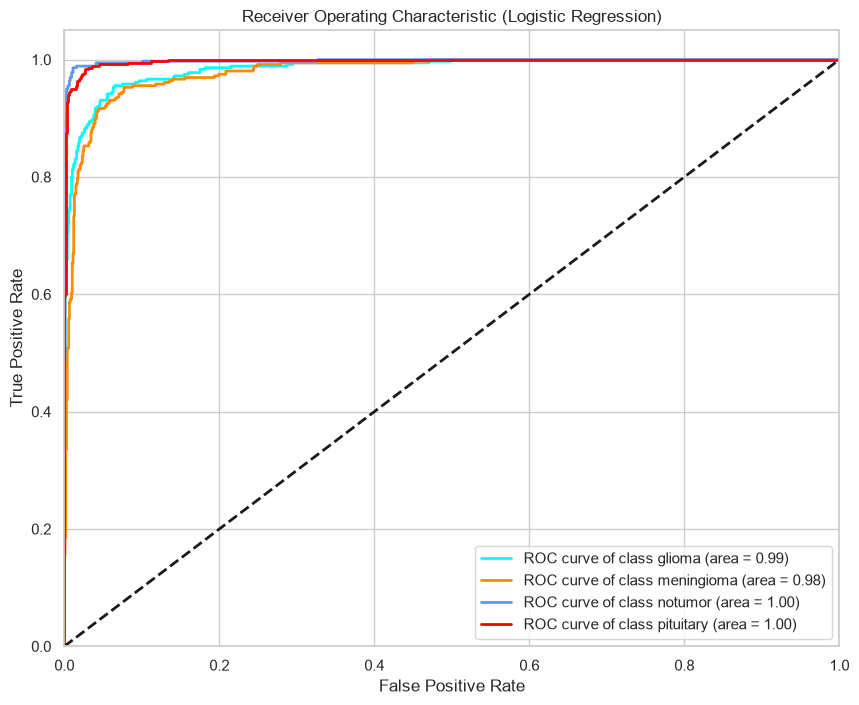

In [12]:
print("Running Phase 11: Multi-Model Linear Probes & ROC...")
X_train, X_test, y_train, y_test = train_test_split(emb_scaled, df['label'], test_size=0.2, random_state=42, stratify=df['label'])

models_dict = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(max_iter=1000),
    "Ridge Classifier": RidgeClassifier(),
    "kNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Nearest Centroid": NearestCentroid()
}

results = {}
for name, m in models_dict.items():
    m.fit(X_train, y_train)
    y_pred = m.predict(X_test)
    f1 = f1_score(y_test, y_pred, average='weighted')
    kappa = cohen_kappa_score(y_test, y_pred)
    results[name] = {'F1': f1, 'Kappa': kappa}

res_df = pd.DataFrame(results).T
print("Model Comparison on Frozen Embeddings:")
print(res_df)

# Plot ROC for Logistic Regression (One vs Rest)
log_reg = models_dict["Logistic Regression"]
y_test_bin = label_binarize(y_test, classes=classes)
y_score = log_reg.predict_proba(X_test)

plt.figure(figsize=(10, 8))
for i, color in zip(range(len(classes)), ['aqua', 'darkorange', 'cornflowerblue', 'red']):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'ROC curve of class {classes[i]} (area = {roc_auc:0.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (Logistic Regression)')
plt.legend(loc="lower right")
plt.savefig("phase11_roc.png")
plt.show()

## Phase 12 & 13: Research Hypothesis Generator & Report
Automatic Generation of Research Report and Hypotheses based on empirical data.

In [13]:
print("Running Phase 12/13: Generating Top-Tier Research Report & Hypotheses...")
hypotheses = []
if acc_meta > 0.6:
    hypotheses.append({
        "Hypothesis": "Severe Dataset Bias Exists.",
        "Evidence": f"Metadata (resolution, brightness) alone predicts class with {acc_meta*100:.1f}% accuracy.",
        "Experiment": "Debias the dataset by equalizing resolution and intensity histograms before training any CNN.",
        "Architecture": "Use Domain Adversarial Neural Networks (DANN) to unlearn metadata bias."
    })

f1_logreg = results['Logistic Regression']['F1']
if f1_logreg > 0.85:
    hypotheses.append({
        "Hypothesis": "Deep CNNs may be overkill.",
        "Evidence": f"A linear probe on ImageNet embeddings achieves F1={f1_logreg:.3f}. The classes are linearly separable.",
        "Experiment": "Compare a simple Logistic Regression on embeddings vs a fully fine-tuned ViT. If margins are <3%, prioritize lightweight models.",
        "Architecture": "Lightweight MobileNetV3 or purely traditional ML on deep features."
    })

if tw > 0.90:
    hypotheses.append({
        "Hypothesis": "Natural clustering correlates strongly with MRI Orientation.",
        "Evidence": f"UMAP trustworthiness is very high ({tw:.3f}), implying strong local neighborhood preservation.",
        "Experiment": "Perform unsupervised orientation discovery (Axial/Coronal/Sagittal) and train separate expert models for each view.",
        "Architecture": "Mixture of Experts (MoE) where gating network routes based on anatomical orientation."
    })

report_content = f"""# Brain Tumor MRI - Top-Tier Research Report & Protocol

## Phase 1-5: Data Integrity & Anatomy
- Total Valid Images: {len(df)}
- Corrupted Images: {len(corrupted)}
- Near Duplicates Found: {len(duplicates)}
- Average Brain Symmetry (IoU): {df['symmetry'].mean():.3f}

## Phase 6-10: Feature Space & Bias
- Extracted Embeddings Shape: {embeddings.shape}
- UMAP Trustworthiness: {tw:.3f}
- Metadata Predictivity (Bias Risk): {acc_meta*100:.1f}%
- Isolation Forest Outliers: {num_iso_outliers}
- Local Outlier Factor (LOF) Outliers: {num_lof_outliers}

## Phase 11: Linear Probe Separability
| Model | F1 Score | Cohen's Kappa |
|-------|----------|---------------|
"""
for name, metric in results.items():
    report_content += f"| {name} | {metric['F1']:.3f} | {metric['Kappa']:.3f} |\n"

report_content += "\n## Phase 13: Auto-Generated Research Hypotheses\n"
for i, hyp in enumerate(hypotheses, 1):
    report_content += f"### Hypothesis {i}: {hyp['Hypothesis']}\n"
    report_content += f"- **Evidence**: {hyp['Evidence']}\n"
    report_content += f"- **Suggested Experiment**: {hyp['Experiment']}\n"
    report_content += f"- **Suggested Architecture**: {hyp['Architecture']}\n\n"

with open("dataset_analysis_report.md", "w") as f:
    f.write(report_content)

print("Report generated successfully: dataset_analysis_report.md")

Running Phase 12/13: Generating Top-Tier Research Report & Hypotheses...
Report generated successfully: dataset_analysis_report.md
